# hw2: Решающие деревья

*Спасибо великому курсу великого Евгения Соколова*

### О задании

Задание состоит из двух разделов:
1. В первом разделе вы научитесь применять деревья из sklearn для задачи классификации. Вы посмотрите какие разделяющие поверхности деревья строят для различных датасетов и проанализируете их зависимость от различных гиперпараметров.
2. Во втором разделе вы попробуете реализовать свое решающее дерево и сравните его со стандартное имплементацией из sklearn. Вы также протестируете деревья на более сложных датасетах и сравните различные подходы к кодированию категориальных признаков.

Все данные, на которых будут обучаться модели, вы можете найти на диске.

### Оценивание и штрафы
Каждая из задач имеет определенную «стоимость» (указана в скобках около задачи). Максимально допустимая оценка за работу — 10 баллов. Неэффективная и/или неоригинальная реализация кода может негативно отразиться на оценке.

### Формат сдачи
Заполненный ноутбук ```hw2-trees.ipynb``` и модуль с реализованными функциями и классами ```hw2code.py``` необходимо загрузить на свой Github. Затем нужно оставить комментарий в Google-таблице с оценками в столбце <<hw2>> в строке со своей фамилией о том, что вы выполнили работу с указанием ника на Kaggle. 

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import accuracy_score, make_scorer
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from sklearn.pipeline import make_pipeline
from hw2code import DecisionTree, find_best_split

sns.set(style='whitegrid')

# 1. Решающие деревья. Визуализация.

В этой части мы рассмотрим два простых двумерных датасета сделанных с помощью `make_moons`, `make_circles` и посмотрим как ведет себя разделяющая поверхность в зависимости от различных гиперпараметров.

In [2]:
from sklearn.datasets import make_moons, make_circles, make_classification

datasets = [
    make_circles(noise=0.2, factor=0.5, random_state=42),
    make_moons(noise=0.2, random_state=42),
    make_classification(n_classes=3, n_clusters_per_class=1, n_features=2,
                        class_sep=0.8, random_state=3, n_redundant=0)
]
dataset_names = ['circles', 'moons', 'classification']

In [3]:
palette = sns.color_palette(n_colors=3)
cmap = ListedColormap(palette)

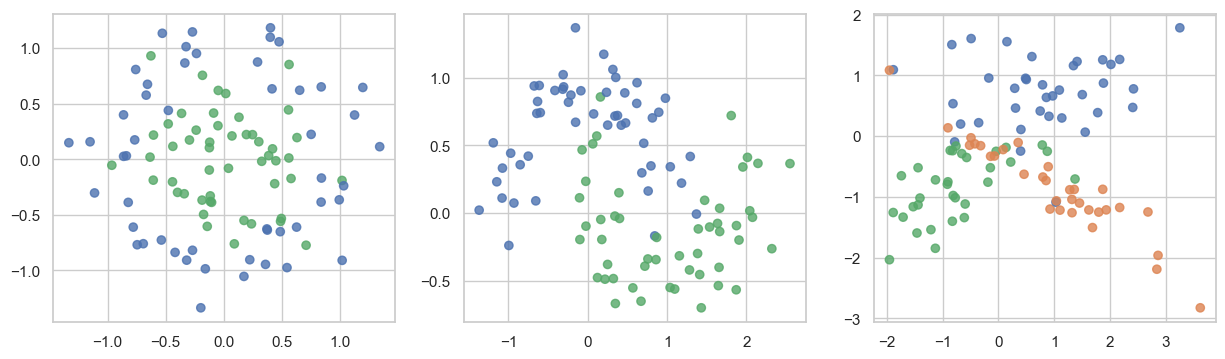

In [4]:
plt.figure(figsize=(15, 4))
for i, (x, y) in enumerate(datasets):
    plt.subplot(1, 3, i + 1)
    plt.scatter(x[:, 0], x[:, 1], c=y, cmap=cmap, alpha=.8)

__Задание 1. (1 балл)__

Для каждого датасета обучите решающее дерево с параметрами по умолчанию, предварительно разбив выборку на обучающую и тестовую. Постройте разделящие поверхности (для этого воспользуйтесь функцией `plot_surface`, пример ниже). Посчитайте accuracy на обучающей и тестовой выборках. Сильно ли деревья переобучились?

In [5]:
def plot_surface(clf, X, y):
    plot_step = 0.01
    palette = sns.color_palette(n_colors=len(np.unique(y)))
    cmap = ListedColormap(palette)
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, plot_step),
                         np.arange(y_min, y_max, plot_step))
    plt.tight_layout(h_pad=0.5, w_pad=0.5, pad=2.5)

    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    cs = plt.contourf(xx, yy, Z, cmap=cmap, alpha=0.3)

    plt.scatter(X[:, 0], X[:, 1], c=y, cmap=cmap, alpha=.7,
                edgecolors=np.array(palette)[y], linewidths=2)

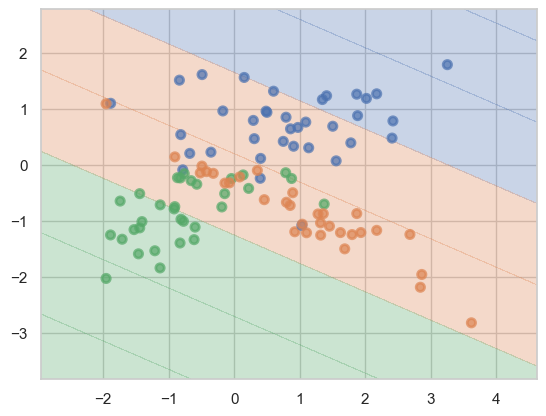

In [6]:
from sklearn.linear_model import LinearRegression

X, y = datasets[2]
lr = LinearRegression().fit(X, y)
plot_surface(lr, X, y)
plt.show()

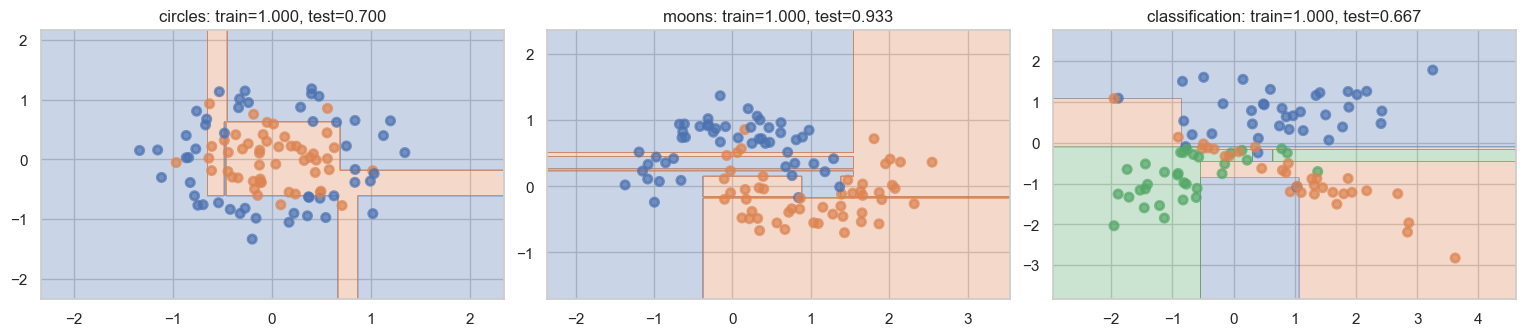

,train_accuracy,test_accuracy
dataset,,
circles,1.0,0.700000
moons,1.0,0.933333
classification,1.0,0.666667


In [7]:
splits = [
    train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
    for X, y in datasets
]
default_results = []
plt.figure(figsize=(16, 4))

for i, (name, (X, y), split) in enumerate(zip(dataset_names, datasets, splits)):
    X_train, X_test, y_train, y_test = split
    model = DecisionTreeClassifier(random_state=42).fit(X_train, y_train)
    train_accuracy = accuracy_score(y_train, model.predict(X_train))
    test_accuracy = accuracy_score(y_test, model.predict(X_test))
    default_results.append({
        'dataset': name,
        'train_accuracy': train_accuracy,
        'test_accuracy': test_accuracy
    })
    plt.subplot(1, 3, i + 1)
    plot_surface(model, X, y)
    plt.title(f'{name}: train={train_accuracy:.3f}, test={test_accuracy:.3f}')

plt.show()
default_results = pd.DataFrame(default_results).set_index('dataset')
display(default_results)

__Ответ:__ На обучающей выборке accuracy всех деревьев равна 1. На тестовой: circles — 0.700, moons — 0.933, classification — 0.667. На circles и classification заметно сильное переобучение: дерево запомнило обучающие объекты, но хуже предсказывает новые. На moons разрыв небольшой. Без ограничений на поверхности появляются мелкие прямоугольные области вокруг отдельных объектов.

__Задание 2. (1.5 балла)__

Попробуйте перебрать несколько параметров для регуляризации (напр. `max_depth`, `min_samples_leaf`). Для каждого набора гиперпараметров постройте разделяющую поверхность, выведите обучающую и тестовую ошибки. Можно делать кросс-валидацию или просто разбиение на трейн и тест, главное делайте каждый раз одинаковое разбиение, чтобы можно было корректно сравнивать (помните же, что итоговое дерево сильно зависит от небольшого изменения обучающей выборки?). Проследите как меняется разделяющая поверхность и обобщающая способность. Почему так происходит, одинаково ли изменение для разных датасетов?

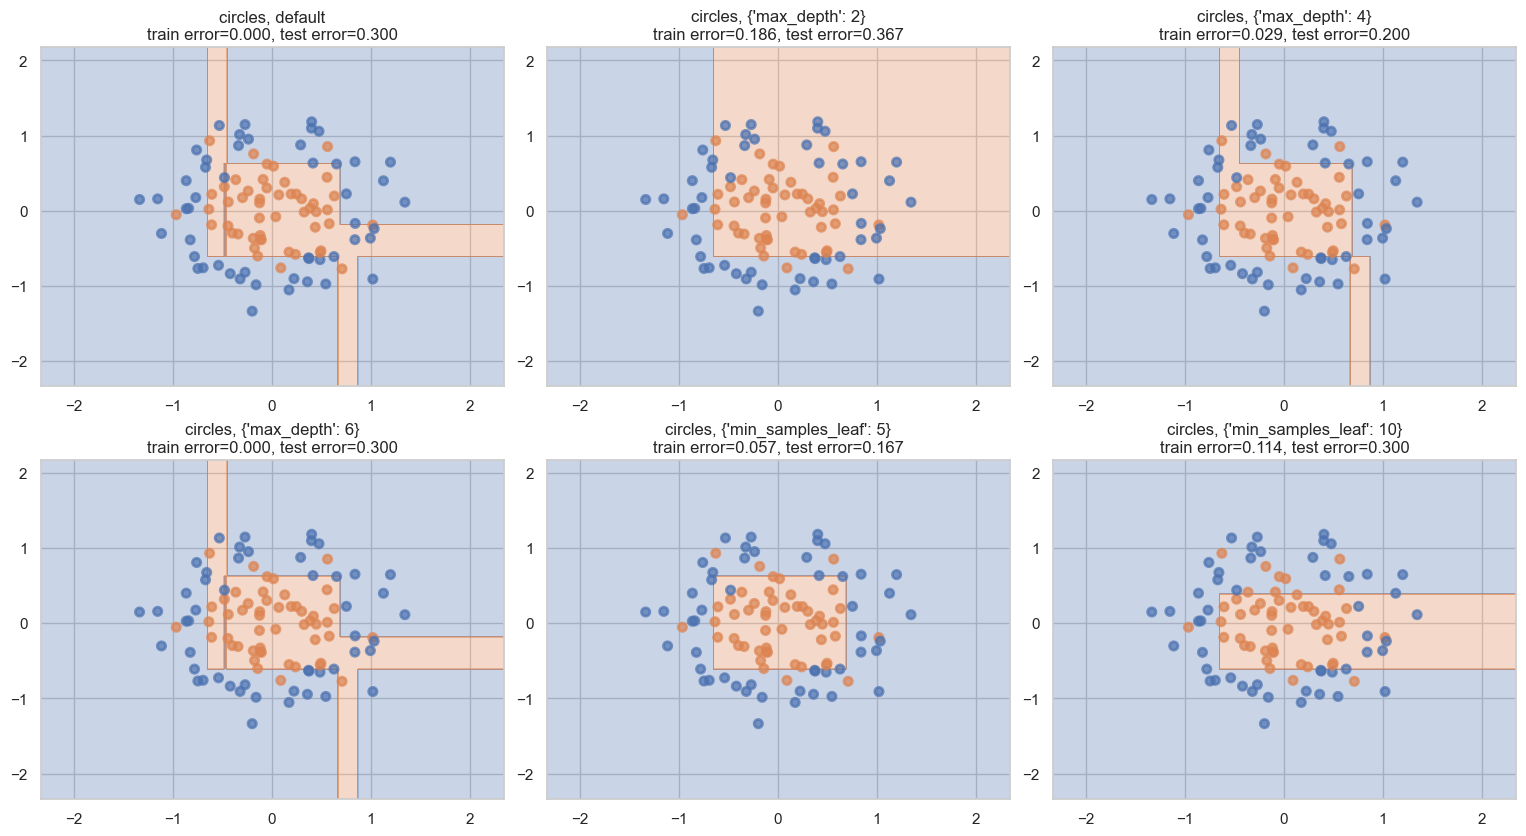

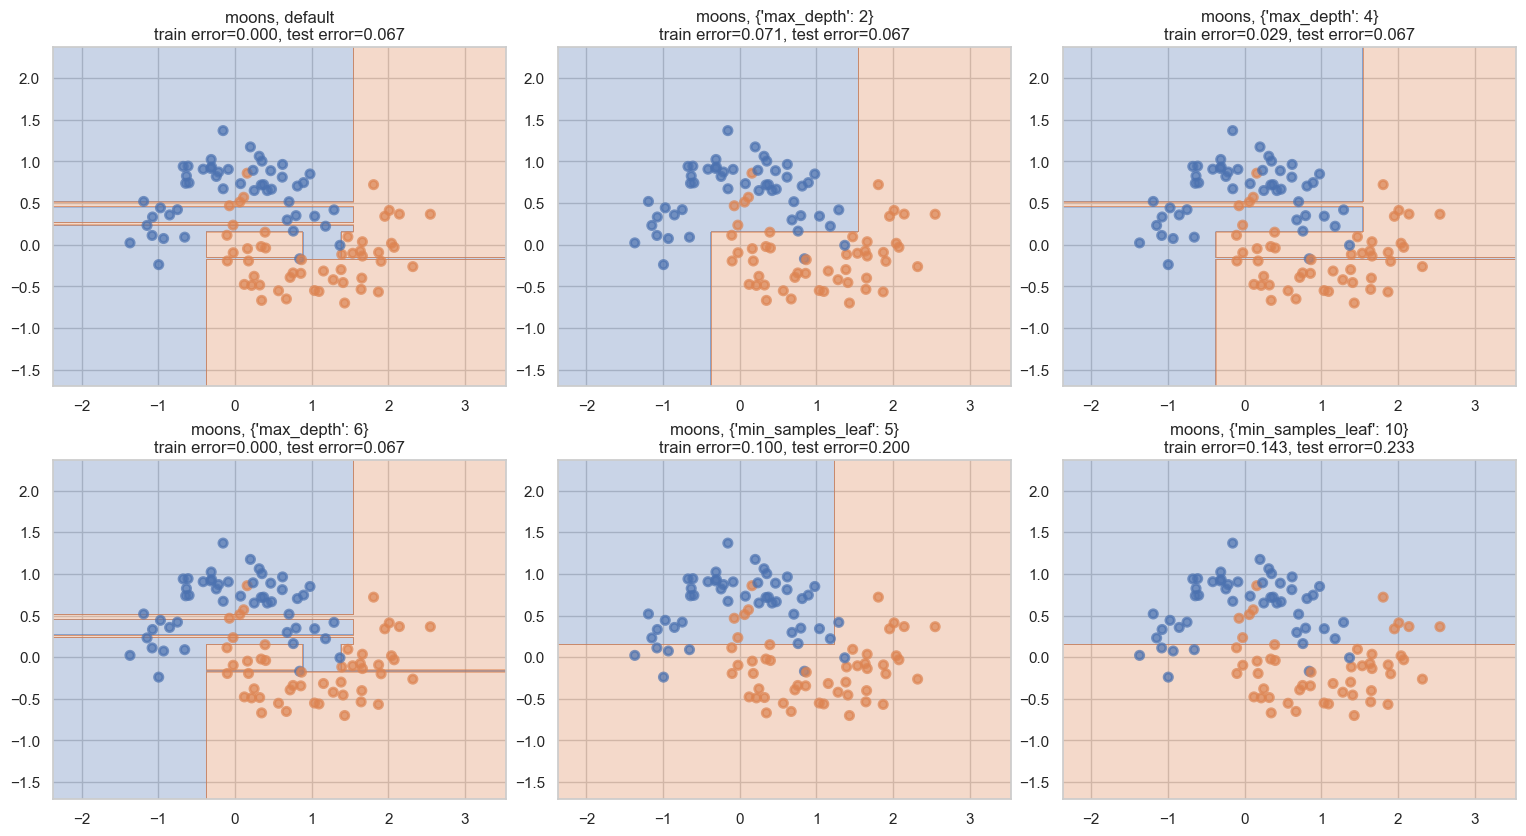

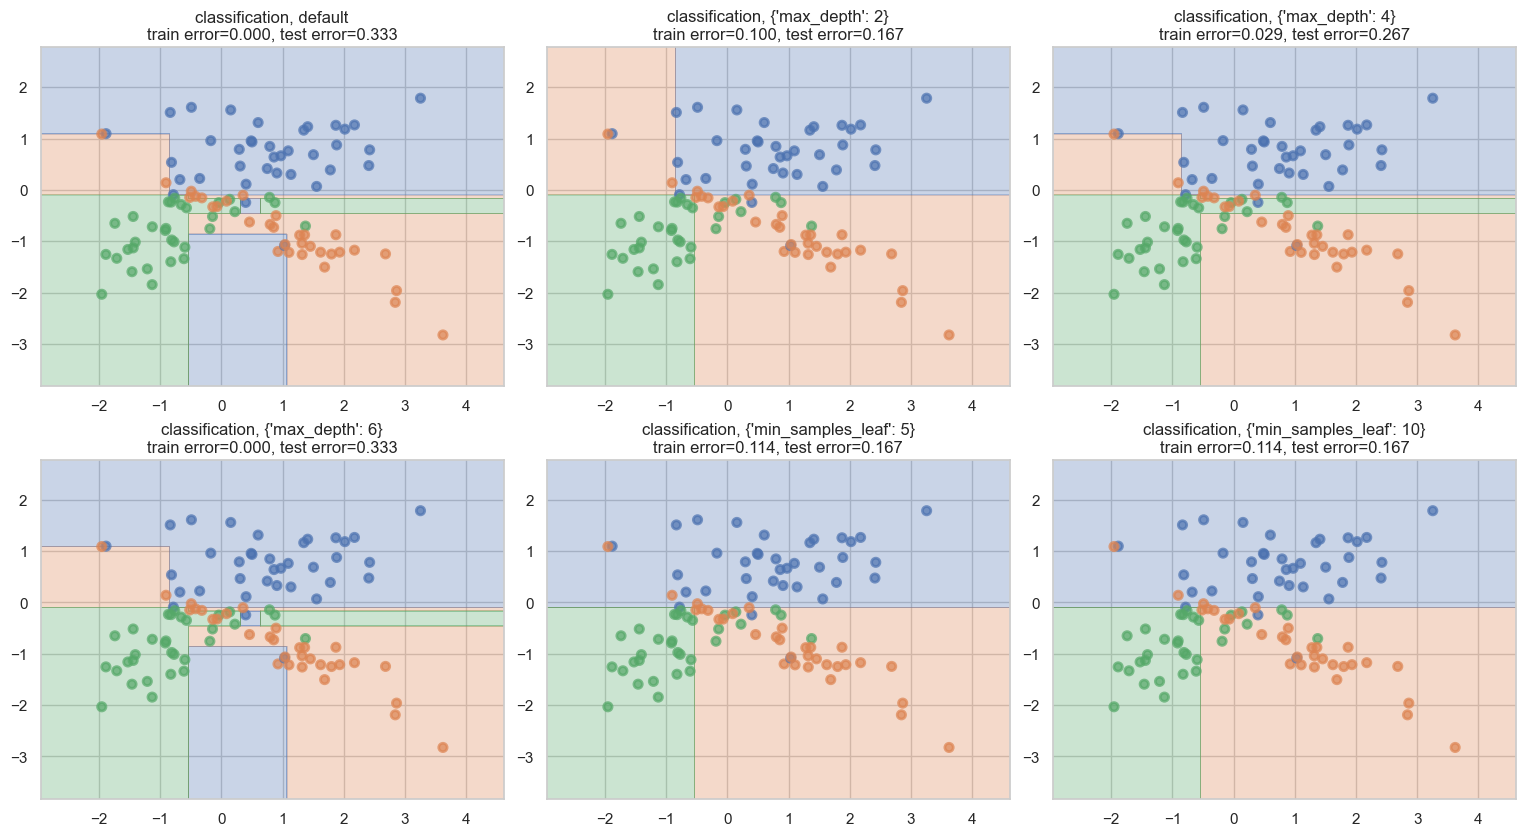

,dataset,parameters,train_error,test_error
0,circles,default,0.000000,0.300000
1,circles,{'max_depth': 2},0.185714,0.366667
2,circles,{'max_depth': 4},0.028571,0.200000
3,circles,{'max_depth': 6},0.000000,0.300000
4,circles,{'min_samples_leaf': 5},0.057143,0.166667
5,circles,{'min_samples_leaf': 10},0.114286,0.300000
6,moons,default,0.000000,0.066667
7,moons,{'max_depth': 2},0.071429,0.066667
8,moons,{'max_depth': 4},0.028571,0.066667
9,moons,{'max_depth': 6},0.000000,0.066667


In [8]:
parameter_sets = [
    {},
    {'max_depth': 2},
    {'max_depth': 4},
    {'max_depth': 6},
    {'min_samples_leaf': 5},
    {'min_samples_leaf': 10}
]
regularization_results = []

for name, (X, y), split in zip(dataset_names, datasets, splits):
    X_train, X_test, y_train, y_test = split
    plt.figure(figsize=(16, 9))
    for i, parameters in enumerate(parameter_sets):
        model = DecisionTreeClassifier(random_state=42, **parameters).fit(X_train, y_train)
        train_error = 1 - accuracy_score(y_train, model.predict(X_train))
        test_error = 1 - accuracy_score(y_test, model.predict(X_test))
        label = str(parameters) if parameters else 'default'
        regularization_results.append({
            'dataset': name,
            'parameters': label,
            'train_error': train_error,
            'test_error': test_error
        })
        plt.subplot(2, 3, i + 1)
        plot_surface(model, X, y)
        plt.title(f'{name}, {label}\ntrain error={train_error:.3f}, test error={test_error:.3f}')
    plt.show()

regularization_results = pd.DataFrame(regularization_results)
display(regularization_results)

__Ответ:__ Ограничение глубины и увеличение минимального числа объектов в листе упрощают разделяющую поверхность: исчезают мелкие области, уменьшается подстройка под шум. Обучающая ошибка обычно растёт, а тестовая может уменьшиться; слишком сильные ограничения приводят к недообучению.

На circles тестовая ошибка уменьшается с 0.300 до 0.200 при max_depth=4 и до 0.167 при min_samples_leaf=5. Глубины 2 недостаточно для приближения круговой границы, ошибка равна 0.367. На moons ограничение глубины до 2 или 4 сохраняет тестовую ошибку 0.067, а min_samples_leaf=10 увеличивает её до 0.233. На classification max_depth=2 уменьшает ошибку с 0.333 до 0.167. Эффект различается из-за формы границ классов, шума и малого размера тестовых выборок; одинаковая регуляризация подходит им по-разному.

# 2. Решающие деревья своими руками

В этой части вам нужно реализовать свой класс для обучения решающего дерева в задаче бинарной классификации с возможностью обработки вещественных и категориальных признаков.

__Задание 3. (1.5 балл)__

Реализуйте функцию find_best_split из модуля hw2code.py

__Задание 4. (0.5 балла)__

Загрузите таблицу students.csv (это немного преобразованный датасет [User Knowledge](https://archive.ics.uci.edu/ml/datasets/User+Knowledge+Modeling)). В ней признаки объекта записаны в первых пяти столбцах, а в последнем записана целевая переменная (класс: 0 или 1). Постройте на одном изображении пять кривых "порог — значение критерия Джини" для всех пяти признаков. Отдельно визуализируйте scatter-графики "значение признака — класс" для всех пяти признаков.

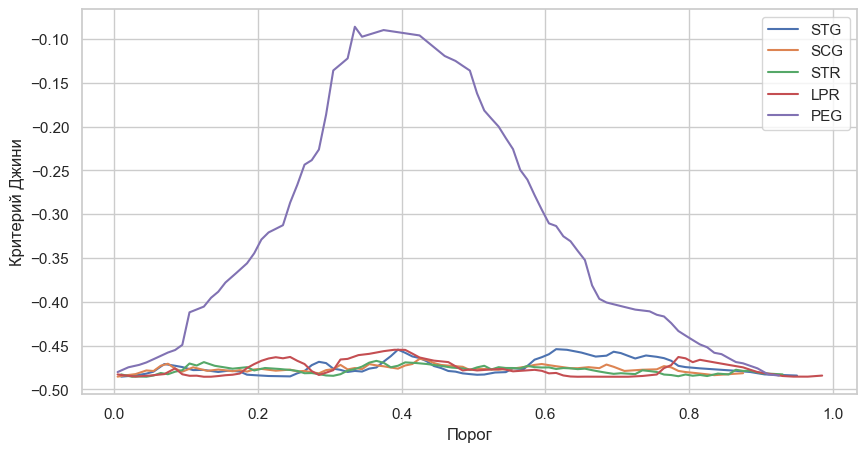

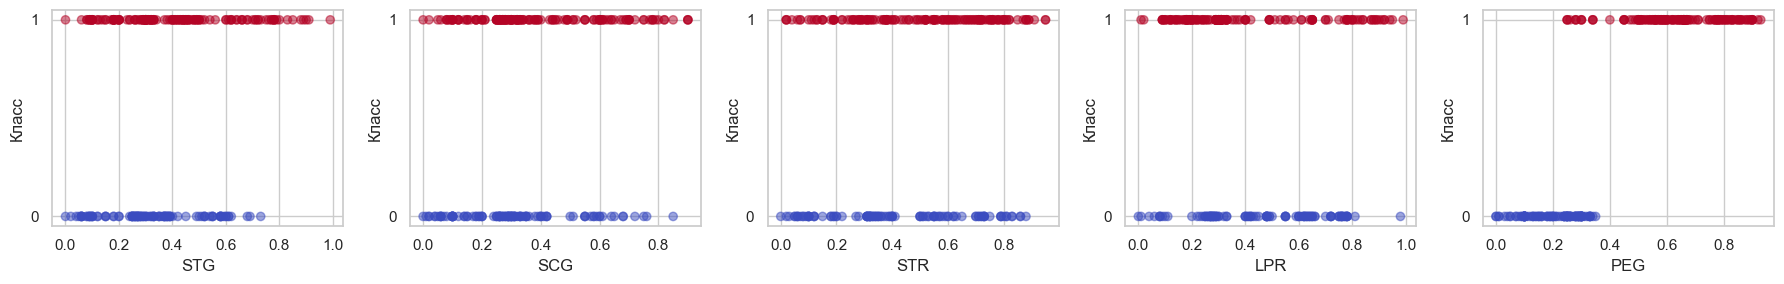

,threshold,gini
feature,,
STG,0.615,-0.453977
SCG,0.425,-0.465019
STR,0.365,-0.467338
LPR,0.390,-0.454668
PEG,0.335,-0.086066


In [9]:
students = pd.read_csv('datasets/students.csv')
X_students = students.iloc[:, :-1]
y_students = students.iloc[:, -1].to_numpy()
student_splits = []

plt.figure(figsize=(10, 5))
for feature in X_students.columns:
    thresholds, ginis, threshold_best, gini_best = find_best_split(
        X_students[feature].to_numpy(), y_students
    )
    plt.plot(thresholds, ginis, label=feature)
    student_splits.append({
        'feature': feature,
        'threshold': threshold_best,
        'gini': gini_best
    })

plt.xlabel('Порог')
plt.ylabel('Критерий Джини')
plt.legend()
plt.show()

fig, axes = plt.subplots(1, 5, figsize=(18, 3))
for feature, ax in zip(X_students.columns, axes):
    ax.scatter(X_students[feature], y_students, c=y_students, cmap='coolwarm', alpha=0.5)
    ax.set_xlabel(feature)
    ax.set_ylabel('Класс')
    ax.set_yticks([0, 1])
plt.tight_layout()
plt.show()

student_splits = pd.DataFrame(student_splits).set_index('feature')
display(student_splits)

__Задание 5. (0.5 балла)__

Исходя из кривых значений критерия Джини, по какому признаку нужно производить деление выборки на два поддерева? Согласуется ли этот результат с визуальной оценкой scatter-графиков? Как бы охарактеризовали вид кривой для "хороших" признаков, по которым выборка делится почти идеально? Чем отличаются кривые для признаков, по которым деление практически невозможно?

**Ответ:** Делить следует по PEG с порогом 0.335: здесь критерий Джини максимален и равен примерно −0.086, тогда как лучшие значения остальных признаков лежат около −0.45…−0.47. Это согласуется со scatter-графиками: малые значения PEG преимущественно относятся к классу 0, большие — к классу 1; у остальных признаков классы сильно перекрываются.

Для хорошего признака есть выраженный максимум критерия, близкий к нулю: после разбиения подвыборки почти чистые. У слабого признака кривая меняется мало и остаётся около отрицательной нечистоты исходной выборки. Здесь выбирается максимум, поскольку взвешенная нечистота взята со знаком минус.

__Задание 6. (1.5 балла).__

Разберитесь с уже написанным кодом в классе DecisionTree модуля hw2code.py. Найдите ошибки в реализации метода \_fit_node. Напишите функцию \_predict_node.

 Построение дерева осуществляется согласно базовому жадному алгоритму, предложенному в лекции. Выбор лучшего разбиения необходимо производить по критерию Джини. Критерий останова: все объекты в листе относятся к одному классу или ни по одному признаку нельзя разбить выборку. Ответ в листе: наиболее часто встречающийся класс в листе. Для категориальных признаков выполняется преобразование, описанное в лекции в разделе «Учет категориальных признаков».

__Задание 7. (0.5 балла)__

Протестируйте свое решающее дерево на датасете [mushrooms](https://archive.ics.uci.edu/ml/datasets/Mushroom). Вам нужно скачать таблицу agaricus-lepiota.data (лежит на гитхабе вместе с заданием), прочитать ее с помощью pandas, применить к каждому столбцу LabelEncoder (из sklearn), чтобы преобразовать строковые имена категорий в натуральные числа. Первый столбец — это целевая переменная (e — edible, p — poisonous) Мы будем измерять качество с помощью accuracy, так что нам не очень важно, что будет классом 1, а что — классом 0. Обучите решающее дерево на половине случайно выбранных объектов (признаки в датасете категориальные) и сделайте предсказания для оставшейся половины. Вычислите accuracy.

У вас должно получиться значение accuracy, равное единице (или очень близкое к единице), и не очень глубокое дерево.

In [10]:
mushrooms = pd.read_csv('datasets/agaricus-lepiota.data', header=None)
mushrooms_encoded = mushrooms.apply(lambda column: LabelEncoder().fit_transform(column))
X_mushrooms = mushrooms_encoded.iloc[:, 1:].to_numpy()
y_mushrooms = mushrooms_encoded.iloc[:, 0].to_numpy()
X_train, X_test, y_train, y_test = train_test_split(
    X_mushrooms, y_mushrooms, test_size=0.5, random_state=42, stratify=y_mushrooms
)
mushroom_tree = DecisionTree(['categorical'] * X_mushrooms.shape[1]).fit(X_train, y_train)
mushroom_accuracy = accuracy_score(y_test, mushroom_tree.predict(X_test))


def tree_depth(node):
    if node['type'] == 'terminal':
        return 0
    return 1 + max(tree_depth(node['left_child']), tree_depth(node['right_child']))


print(f'Accuracy: {mushroom_accuracy:.4f}')
print(f'Глубина дерева: {tree_depth(mushroom_tree._tree)}')

Accuracy: 1.0000
Глубина дерева: 7


__Задание 8. (бонус, 1 балл)__

Реализуйте в классе DecisionTree поддержку параметров max_depth, min_samples_split и min_samples_leaf по аналогии с DecisionTreeClassifier. Постройте графики зависимости качества предсказания в зависимости от этих параметров для набора данных tic-tac-toe (см. следующий пункт).

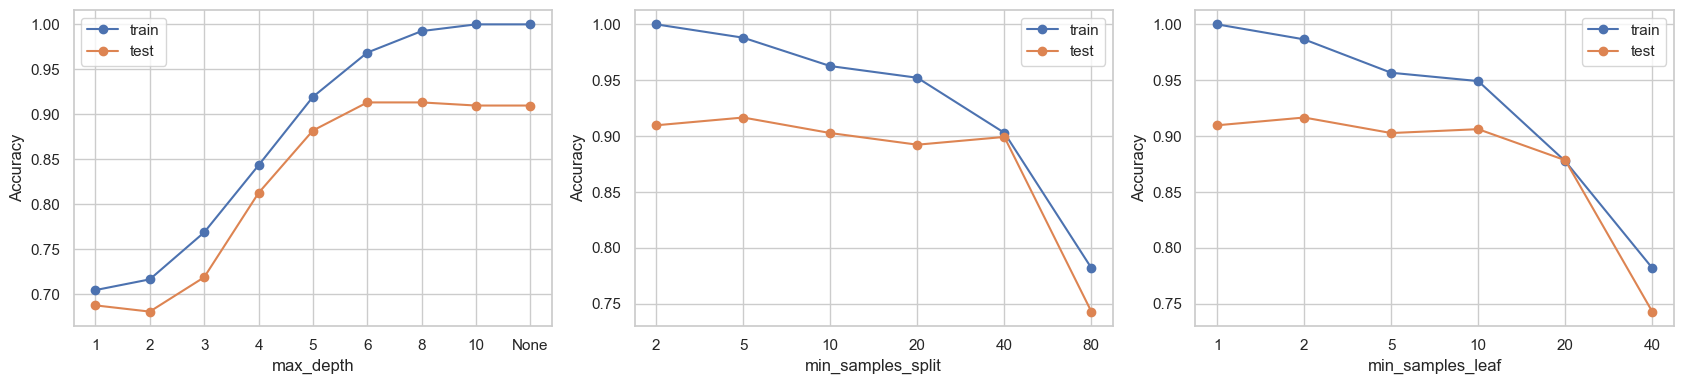

In [11]:
tic_tac_toe = pd.read_csv('datasets/tic-tac-toe-endgame.csv')
tic_encoded = tic_tac_toe.apply(lambda column: LabelEncoder().fit_transform(column))
X_tic = tic_encoded.iloc[:, :-1].to_numpy()
y_tic = tic_encoded.iloc[:, -1].to_numpy()
X_train, X_test, y_train, y_test = train_test_split(
    X_tic, y_tic, test_size=0.3, random_state=42, stratify=y_tic
)
parameter_values = {
    'max_depth': [1, 2, 3, 4, 5, 6, 8, 10, None],
    'min_samples_split': [2, 5, 10, 20, 40, 80],
    'min_samples_leaf': [1, 2, 5, 10, 20, 40]
}
bonus_results = []
fig, axes = plt.subplots(1, 3, figsize=(17, 4))

for (parameter, values), ax in zip(parameter_values.items(), axes):
    train_scores, test_scores = [], []
    for value in values:
        model = DecisionTree(['categorical'] * X_tic.shape[1], **{parameter: value})
        model.fit(X_train, y_train)
        train_score = accuracy_score(y_train, model.predict(X_train))
        test_score = accuracy_score(y_test, model.predict(X_test))
        train_scores.append(train_score)
        test_scores.append(test_score)
        bonus_results.append({
            'parameter': parameter,
            'value': value,
            'train_accuracy': train_score,
            'test_accuracy': test_score
        })
    positions = np.arange(len(values))
    ax.plot(positions, train_scores, marker='o', label='train')
    ax.plot(positions, test_scores, marker='o', label='test')
    ax.set_xticks(positions, [str(value) for value in values])
    ax.set_xlabel(parameter)
    ax.set_ylabel('Accuracy')
    ax.legend()

plt.tight_layout()
plt.show()

__Задание 9. (2 балла)__

Загрузите следующие наборы данных (напомним, что pandas умеет загружать файлы по url, в нашем случае это файл \*.data), предварительно ознакомившись с описанием признаков и целевой переменной в каждом из них (она записаны в Data Folder, в файле *.names): 
* [mushrooms](https://archive.ics.uci.edu/ml/datasets/Mushroom) (загрузили в предыдущем пункте, классы записаны в нулевом столбце)
* [tic-tac-toe](https://archive.ics.uci.edu/ml/datasets/Tic-Tac-Toe+Endgame) (классы записаны в последнем столбце, датасет лежит на гитхабе вместе с заданием)
* [cars](https://archive.ics.uci.edu/ml/datasets/Car+Evaluation) (классы записаны в последнем столбце, считаем что unacc, acc — это класс 0, good, vgood — класс 1)
* [nursery](https://archive.ics.uci.edu/ml/datasets/Nursery) (классы записаны в последнем столбце, считаем, что not_recom и recommend — класс 0, very_recom, priority, spec_prior — класс 1).

Закодируйте категориальные признаки, использовав LabelEncoder. С помощью cross_val_score (cv=10) оцените accuracy на каждом из этих наборов данных следующих алгоритмов:
* DecisionTree, считающий все признаки вещественными
* DecisionTree, считающий все признаки категориальными
* DecisionTree, считающий все признаки вещественными + one-hot-encoding всех признаков
* DecisionTreeClassifier из sklearn. Запишите результат в pd.DataFrame (по строкам — наборы данных, по столбцам — алгоритмы).

Рекомендации:
* Чтобы cross_val_score вычисляла точность, нужно передать scoring=make_scorer(accuracy_score), обе фукнции из sklearn.metrics.
* Если вам позволяет память (а она скорее всего позволяет), указывайте параметр sparse=False в OneHotEncoder (если вы, конечно, используете его). Иначе вам придется добиваться того, чтобы ваша реализация дерева умела работать с разреженными матрицами (что тоже, в целом, не очень сложно).

In [12]:
cars = pd.read_csv('datasets/car.data', header=None)
nursery = pd.read_csv('datasets/nursery.data', header=None)
X_cars = cars.iloc[:, :-1].apply(lambda column: LabelEncoder().fit_transform(column)).to_numpy()
y_cars = cars.iloc[:, -1].map({'unacc': 0, 'acc': 0, 'good': 1, 'vgood': 1}).to_numpy()
X_nursery = nursery.iloc[:, :-1].apply(lambda column: LabelEncoder().fit_transform(column)).to_numpy()
y_nursery = nursery.iloc[:, -1].map({
    'not_recom': 0, 'recommend': 0, 'very_recom': 1, 'priority': 1, 'spec_prior': 1
}).to_numpy()
comparison_datasets = {
    'mushrooms': (X_mushrooms, y_mushrooms),
    'tic-tac-toe': (X_tic, y_tic),
    'cars': (X_cars, y_cars),
    'nursery': (X_nursery, y_nursery)
}
comparison_results = {}
scoring = make_scorer(accuracy_score)

for name, (X, y) in comparison_datasets.items():
    one_hot_width = sum(len(np.unique(X[:, i])) for i in range(X.shape[1]))
    models = {
        'DecisionTree real': DecisionTree(['real'] * X.shape[1]),
        'DecisionTree categorical': DecisionTree(['categorical'] * X.shape[1]),
        'DecisionTree one-hot': make_pipeline(
            OneHotEncoder(sparse_output=False, handle_unknown='ignore'),
            DecisionTree(['real'] * one_hot_width)
        ),
        'DecisionTreeClassifier': DecisionTreeClassifier(random_state=42)
    }
    comparison_results[name] = {
        model_name: cross_val_score(model, X, y, cv=10, scoring=scoring).mean()
        for model_name, model in models.items()
    }

comparison_results = pd.DataFrame.from_dict(comparison_results, orient='index')
display(comparison_results)

,DecisionTree real,DecisionTree categorical,DecisionTree one-hot,DecisionTreeClassifier
mushrooms,0.965556,0.982266,0.967280,0.960384
tic-tac-toe,0.769561,0.821667,0.817489,0.771678
cars,0.945019,0.880431,0.828949,0.942707
nursery,0.999691,0.999846,0.999537,0.999691


__Задание 10. (1 балла)__

Проанализируйте результаты эксперимента. 
Одинаково ли для разных наборов данных ранжируются алгоритмы? 
Порассуждайте, почему так происходит. 

Обратите внимание на значение признаков в разных наборах данных. 
Присутствует ли в результатах какая-то компонента случайности? 
Можно ли повлиять на нее и улушить работу алгоритмов?

**Ответ:** Ранжирование различается. На mushrooms лучше категориальное дерево: 0.9823 против 0.9673 у one-hot, 0.9656 у своего числового дерева и 0.9604 у sklearn. На tic-tac-toe категориальное дерево также первое (0.8217), затем one-hot (0.8175), sklearn (0.7717) и числовое дерево (0.7696). На cars лучше числовые деревья: 0.9450 у своего и 0.9427 у sklearn, против 0.8804 у категориального и 0.8289 у one-hot. На nursery все результаты близки к единице (0.9995–0.9998), поэтому различия здесь малы.

Признаки mushrooms описывают категории свойств грибов; символ «?» сохранён как отдельная категория. В [tic-tac-toe](https://archive.ics.uci.edu/dataset/101/tic+tac+toe+endgame) признаки задают содержимое девяти клеток, а класс означает победу крестиков. У таких категорий нет естественного числового порядка. LabelEncoder задаёт искусственный порядок, и числовой порог разрешает разделять только соседние группы кодов. Категориальное дерево упорядочивает значения по доле положительного класса внутри текущего узла, а one-hot позволяет отделять одну категорию от остальных. Это меняет доступные разбиения и последующие решения жадного алгоритма.

В [cars](https://archive.ics.uci.edu/ml/machine-learning-databases/car/car.names) признаки включают цену, вместимость и безопасность и имеют содержательный порядок, хотя LabelEncoder не обязан его сохранять. Получившаяся нумерация и последовательность разбиений оказались удачнее в данном эксперименте. В [nursery](https://archive.ics.uci.edu/ml/machine-learning-databases/nursery/nursery.names) признаки описывают семью и условия приёма; после объединения классов задача почти полностью разделяется простыми правилами, поэтому кодирование влияет мало. При cv=10 разбиение стратифицированное, но без перемешивания; исходный порядок объектов тоже может влиять на оценки.

Случайная компонента возникает при разделении train/test и выборе sklearn между равноценными разбиениями; результат также зависит от порядка кодов категорий и порядка признаков при равных критериях. Здесь random_state зафиксирован, поэтому результаты воспроизводимы. Для более устойчивой оценки можно использовать повторную стратифицированную кросс-валидацию с перемешиванием, а для улучшения качества — выбирать кодирование и регуляризацию по кросс-валидации, не подбирая их по тестовой выборке.

Вставьте что угодно, описывающее ваши впечатления от этого задания:

Интереснее всего было сравнить способы кодирования категориальных признаков и увидеть, как они меняют качество одного и того же дерева.